In [15]:
from bs4 import BeautifulSoup
import urllib.request
import pandas as pd
import datetime
import requests
from selenium import webdriver
from selenium.webdriver.common.by import By
import time
import random
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import math
from scipy import stats
from statsmodels.formula.api import ols, glm
#버전 차이로 인한 warning문구 생략
import warnings
import matplotlib
warnings.filterwarnings(action='ignore')

In [2]:
import pandas as pd
import glob
import re
from functools import reduce

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import STOPWORDS, WordCloud


In [12]:
file_path = './8장_data/News_Category_Dataset_v3.json'
df = pd.read_json(file_path, lines=True)

In [20]:
stopWords = set(stopwords.words("english"))
lemma = WordNetLemmatizer()

In [119]:
all_link = df['headline']

In [120]:
words = []
for link in all_link:
    #a~Z 소문자부터 대문자까지를 ^로 제외하고 모두를 공백으로 바꾼다.
    EnWords = re.sub(r"[^a-zA-Z]+", " ", str(link))
    #대문자들을 소문자로 바꾸고 단어 단위로 짜른다.
    EnWordsToken = word_tokenize(EnWords.lower())
    #불용어는 자른다. me i my 같은 단어들을 없앤다.
    EnWordsTokenStop = [ w for w in EnWordsToken if w not in stopWords]
    #표제어 추출을 진행한다. 단어의 원래 형태로 해준다.
    EnWordsTokenStopLemma = [ lemma.lemmatize(w) for w in EnWordsTokenStop]
    words.append(EnWordsTokenStopLemma)

In [121]:
words2 = [word for sublist in words for word in sublist]

In [122]:
count = Counter(words2)
count.most_common(10)

word_count = dict()
for tag, counts in count.most_common(50):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

trump : 14418
photo : 12446
new : 9008
video : 6283
say : 5840
day : 5500
woman : 5261
year : 4976
donald : 4849
make : 4496
get : 4434
way : 4141
best : 3899
life : 3736
world : 3463
time : 3429
one : 3402
show : 3385
kid : 3282
people : 3065
thing : 2996
week : 2980
first : 2942
like : 2851
love : 2777
need : 2714
want : 2682
american : 2658
obama : 2611
child : 2567
look : 2559
could : 2553
man : 2454
home : 2408
health : 2394
house : 2386
take : 2361
know : 2360
wedding : 2307
black : 2302
star : 2275
right : 2254
mom : 2239
back : 2236
america : 2219
clinton : 2199
state : 2196
gop : 2163
food : 2155


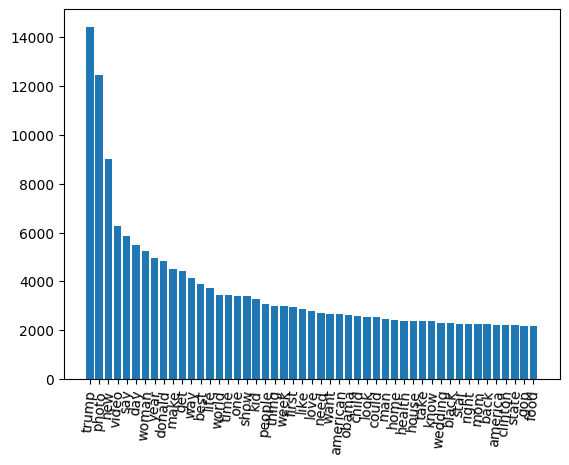

In [123]:
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
#0~len(word_count)만큼 x축에 자리를 만들어놓고 해당 자리에 맞게 갯수를 막대로 채워준다
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
#해당 위치에 맞게 글자를 채워준다.
plt.xticks( range(len(word_count)), list(sorted_Keys), rotation = 85)
plt.show()

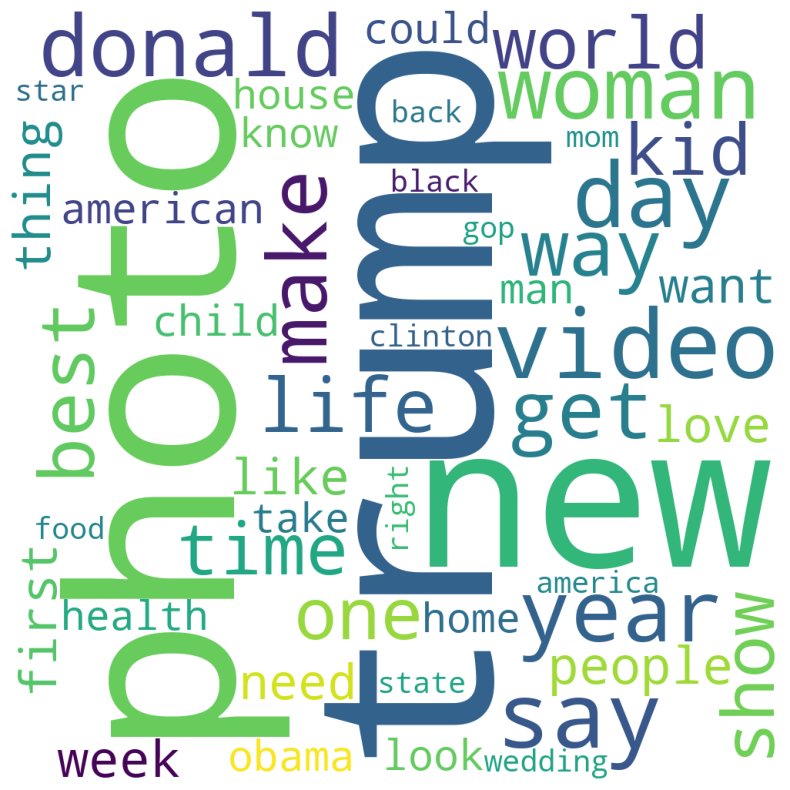

In [124]:
stopwords = set(STOPWORDS)
wc = WordCloud(background_color = 'white', stopwords = stopwords, width = 1000, height = 1000)
cloud = wc.generate_from_frequencies(word_count)
icon = Image.open('./map.jpeg')
plt.figure(figsize = (10,10))
plt.imshow(cloud)
plt.axis('off')
plt.show()

In [ ]:
#일별을 연도별로 나누어줌
df['date'] = pd.to_datetime(df['date'])
df['news_year'] = df['date'].dt.year

In [41]:
df['news_count'] = 0
summary_year = df.groupby('news_year', as_index = False)['news_count'].count()

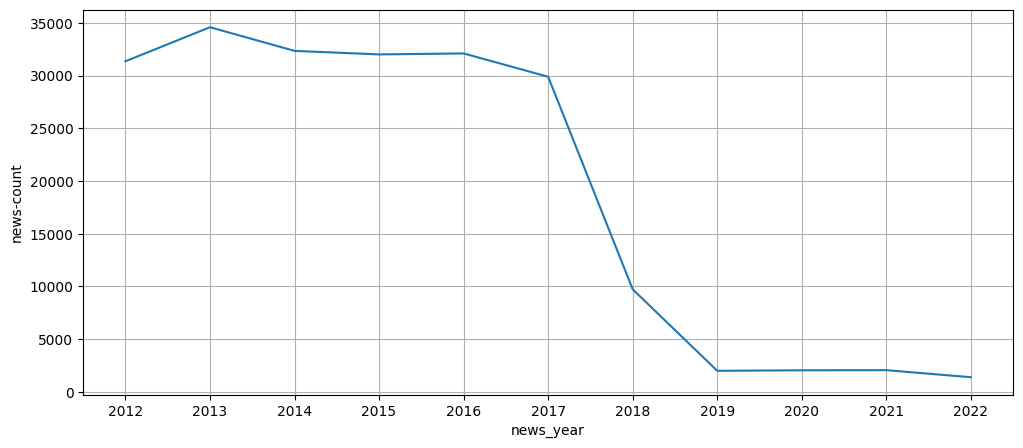

In [40]:
plt.figure(figsize = (12, 5))
plt.xlabel("news_year")
plt.ylabel("news-count")
plt.grid(True)
plt.plot(range(len(summary_year)), summary_year['news_count'])
plt.xticks( range(len(summary_year)), [text for text in summary_year['news_year']])
plt.show()

In [55]:
df.head(10)

,link,headline,category,short_description,authors,date,news_count,news_year
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23,0,2022
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23,0,2022
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23,0,2022
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23,0,2022
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22,0,2022
5,https://www.huffpost.com/entry/belk-worker-fou...,Cleaner Was Dead In Belk Bathroom For 4 Days B...,U.S. NEWS,The 63-year-old woman was seen working at the ...,,2022-09-22,0,2022
6,https://www.huffpost.com/entry/reporter-gets-a...,Reporter Gets Adorable Surprise From Her Boyfr...,U.S. NEWS,"""Who's that behind you?"" an anchor for New Yor...",Elyse Wanshel,2022-09-22,0,2022
7,https://www.huffpost.com/entry/puerto-rico-wat...,Puerto Ricans Desperate For Water After Hurric...,WORLD NEWS,More than half a million people remained witho...,"DÁNICA COTO, AP",2022-09-22,0,2022
8,https://www.huffpost.com/entry/mija-documentar...,How A New Documentary Captures The Complexity ...,CULTURE & ARTS,"In ""Mija,"" director Isabel Castro combined mus...",Marina Fang,2022-09-22,0,2022
9,https://www.huffpost.com/entry/biden-un-russia...,Biden At UN To Call Russian War An Affront To ...,WORLD NEWS,White House officials say the crux of the pres...,"Aamer Madhani, AP",2022-09-21,0,2022


In [130]:
all_author = df['authors']

In [127]:
words_a = []
for link in all_author:
    #a~Z 소문자부터 대문자까지를 ^로 제외하고 모두를 공백으로 바꾼다.
    EnWords = re.sub(r"[^a-zA-Z]+", " ", str(link))
    #대문자들을 소문자로 바꾸고 단어 단위로 짜른다.
    EnWordsToken = word_tokenize(EnWords.lower())
    #불용어는 자른다. me i my 같은 단어들을 없앤다.
    EnWordsTokenStop = [ w for w in EnWordsToken if w not in stopWords]
    #표제어 추출을 진행한다. 단어의 원래 형태로 해준다.
    EnWordsTokenStopLemma = [ lemma.lemmatize(w) for w in EnWordsTokenStop]
    words_a.append(EnWordsTokenStopLemma)

In [49]:
words_a2 = [word for sublist in words_a for word in sublist]

In [131]:
count = Counter(words_a2)
count.most_common(10)

word_count = dict()
for tag, counts in count.most_common(50):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

contributor : 39041
author : 11533
writer : 7922
reuters : 6833
com : 6672
founder : 5171
michael : 3368
lee : 3354
david : 3102
moran : 2990
blogger : 2932
editor : 2784
travel : 2767
contributorauthor : 2679
director : 2673
expert : 2539
food : 2417
speaker : 2312
ron : 2277
mary : 2228
dicker : 2228
dr : 2197
contributorwriter : 2182
rebecca : 2155
professor : 2136
michelle : 2121
ceo : 2084
ryan : 1951
james : 1882
ed : 1852
co : 1829
coach : 1806
ap : 1796
journalist : 1770
university : 1769
sarah : 1742
health : 1671
andy : 1664
sam : 1618
mazza : 1596
lauren : 1596
president : 1596
mom : 1585
papenfuss : 1580
nick : 1578
amanda : 1549
chris : 1487
julia : 1431
oliver : 1406


In [132]:
count.most_common(10)

[('contributor', 39041),
 ('author', 11533),
 ('writer', 7922),
 ('reuters', 6833),
 ('com', 6672),
 ('founder', 5171),
 ('michael', 3368),
 ('lee', 3354),
 ('david', 3102),
 ('moran', 2990)]

In [133]:
word_count2 = word_count
del word_count2['contributor']
del word_count2['author']
del word_count2['writer']
del word_count2['reuters']
del word_count2['com']
del word_count2['founder']

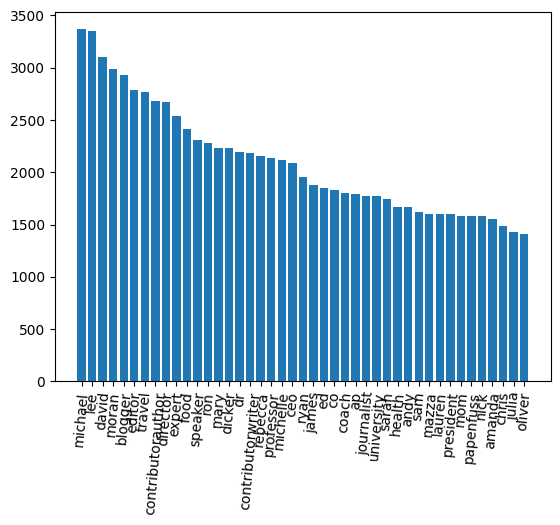

In [134]:
sorted_Keys = sorted(word_count2, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count2.values(), reverse = True)
plt.bar(range(len(word_count2)), sorted_Values, align = 'center')
plt.xticks( range(len(word_count2)), list(sorted_Keys), rotation = 85)
plt.show()

#michael , Lee, david, moran 성씨가 제일 많다

In [107]:
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt
from collections import Counter
from PIL import Image, ImageOps

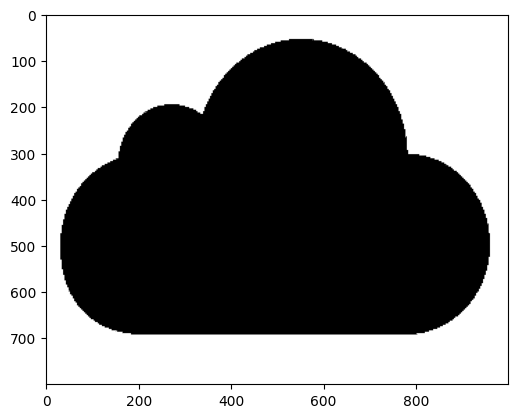

In [128]:
icon = Image.open('./map.png')
plt.imshow(icon)
mask = np.array(icon)

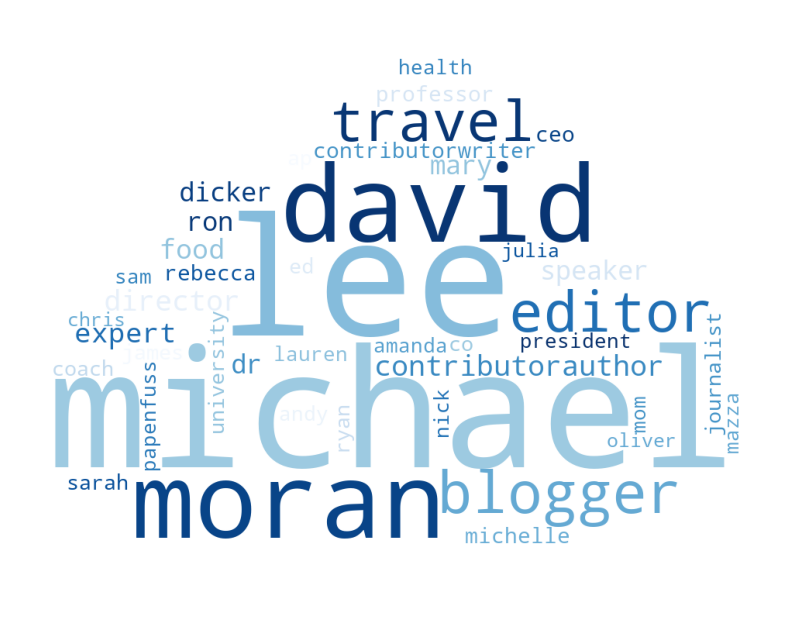

In [140]:
stopwords = set(STOPWORDS)
wc = WordCloud(background_color = 'white', stopwords = stopwords, width = 1000, height = 1000, mask=mask, colormap = 'Blues')
cloud = wc.generate_from_frequencies(word_count)
icon = Image.open('./map.jpeg')
plt.figure(figsize = (10,10))
plt.imshow(cloud)
plt.axis('off')
plt.show()

In [ ]:
from kiwipiepy import Kiwi

In [141]:
pip install kiwipiepy

     ---------------------------------------- 0.0/88.0 MB ? eta -:--:--
     ---------------------------------------- 0.5/88.0 MB 4.2 MB/s eta 0:00:21
      --------------------------------------- 1.6/88.0 MB 4.9 MB/s eta 0:00:18
     - -------------------------------------- 2.6/88.0 MB 4.9 MB/s eta 0:00:18
     - -------------------------------------- 3.7/88.0 MB 4.8 MB/s eta 0:00:18
     -- ------------------------------------- 4.7/88.0 MB 4.9 MB/s eta 0:00:17
     -- ------------------------------------- 6.0/88.0 MB 5.1 MB/s eta 0:00:16
     --- ------------------------------------ 7.3/88.0 MB 5.3 MB/s eta 0:00:16
     --- ------------------------------------ 8.4/88.0 MB 5.4 MB/s eta 0:00:15
     ---- ----------------------------------- 9.7/88.0 MB 5.4 MB/s eta 0:00:15
     ---- ----------------------------------- 10.5/88.0 MB 5.2 MB/s eta 0:00:15
     ----- ---------------------------------- 11.8/88.0 MB 5.3 MB/s eta 0:00:15
     ----- ---------------------------------- 12.8/88.0 M

In [3]:
import json
import re
from konlpy.tag import Okt
from kiwipiepy import Kiwi
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud
import pandas as pd

In [75]:
inputFileName = r"./8장_data/data_analysis_job_postings.csv"
data = pd.read_csv(inputFileName, encoding='utf-8')

In [76]:
description = ''
all_text = " ".join(data['description'].dropna().astype(str))
description = re.sub(r'[^\w]', ' ', all_text)
description

'비즈니스 의사결정을 위한 데이터 분석  리포트 작성  대시보드 구축 업무를 수행합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  Power BI  KPI  Excel 기반으로 KPI 리포트와 월간 성과 분석 자료를 작성합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  사업 성과  매출  비용 데이터를 분석하여 경영진 의사결정을 지원합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  광고 성과와 고객 유입 데이터를 분석하여 마케팅 전략을 개선합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  A B 테스트  대시보드를 활용하여 사용자 행동 데이터를 분석하고 실험 설계를 지원합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  AI 서비스 데이터를 분석하고 생성형 AI 기반 업무 자동화를 지원합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  고객 행동 패턴을 분석하고 서비스 개선을 위한 인사이트를 도출합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  서비스 지표 분석과 A B 테스트를 통해 제품 개선 방향을 제안합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  비즈니스 의사결정을 위한 데이터 분석  리포트 작성  대시보드 구축 업무를 수행합니다  비즈니스 지표를 이해하고 실행 가능한 인사이트를 제안할 수 있어야 합니다  서비스 지표 분석과 A B 테스트를 통해 제품 개선 방향을 제안합니다  문제 정의 능력과 커뮤니케이션 역량을 중요하게 평가합니다  PyTorch  머신러닝를 활용하여 모델 성능 분석과 데이터 품질 개선 업무를 수행합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  Python  Scikit Learn  모델링  머신러닝를 활용하여 예측 모델을 개발하고 실험 결과를 분석합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  Matplotlib  Pandas  Python를 활용하여 서비스 데이터를 분석하고 주요

In [77]:
kiwi = Kiwi()

description_N = [
    token.form
    for token in kiwi.tokenize(description)
    if token.tag.startswith('N')
]
description_N

['비즈니스',
 '의사',
 '결정',
 '데이터',
 '분석',
 '리포트',
 '작성',
 '대시보드',
 '구축',
 '업무',
 '수행',
 '현업',
 '부서',
 '협업',
 '데이터',
 '기반',
 '의사',
 '결정',
 '지원',
 '기반',
 '리포트',
 '월간',
 '성과',
 '분석',
 '자료',
 '작성',
 '신규',
 '데이터',
 '분석',
 '과제',
 '발굴',
 '개선',
 '안',
 '제시',
 '사업',
 '성과',
 '매출',
 '비용',
 '데이터',
 '분석',
 '경영진',
 '의사',
 '결정',
 '지원',
 '현업',
 '부서',
 '협업',
 '데이터',
 '기반',
 '의사',
 '결정',
 '지원',
 '광고',
 '성과',
 '고객',
 '유입',
 '데이터',
 '분석',
 '마케팅',
 '전략',
 '개선',
 '현업',
 '부서',
 '협업',
 '데이터',
 '기반',
 '의사',
 '결정',
 '지원',
 '테스트',
 '대시보드',
 '활용',
 '사용자',
 '행동',
 '데이터',
 '분석',
 '실험',
 '설계',
 '지원',
 '신규',
 '데이터',
 '분석',
 '과제',
 '발굴',
 '개선',
 '안',
 '제시',
 '서비스',
 '데이터',
 '분석',
 '생성',
 '기반',
 '업무',
 '자동',
 '지원',
 '현업',
 '부서',
 '협업',
 '데이터',
 '기반',
 '의사',
 '결정',
 '지원',
 '고객',
 '행동',
 '패턴',
 '분석',
 '서비스',
 '개선',
 '인사이트',
 '도출',
 '현업',
 '부서',
 '협업',
 '데이터',
 '기반',
 '의사',
 '결정',
 '지원',
 '서비스',
 '지표',
 '분석',
 '테스트',
 '제품',
 '개선',
 '방향',
 '제안',
 '신규',
 '데이터',
 '분석',
 '과제',
 '발굴',
 '개선',
 '안',
 '제시',
 '비즈니스',
 '의사',
 '결정',
 '데이

In [78]:
count = Counter(description_N)
count #출력하여 내용 확인

Counter({'데이터': 2590,
         '분석': 2242,
         '업무': 957,
         '개선': 893,
         '기반': 742,
         '지표': 734,
         '활용': 723,
         '지원': 684,
         '비즈니스': 661,
         '인사이트': 654,
         '의사': 607,
         '결정': 607,
         '관리': 587,
         '고객': 522,
         '제안': 520,
         '품질': 510,
         '문제': 495,
         '부서': 488,
         '서비스': 459,
         '가능': 452,
         '자동': 443,
         '리포트': 436,
         '이해': 426,
         '실행': 426,
         '수': 426,
         '우대': 412,
         '정의': 410,
         '능력': 410,
         '커뮤니케이션': 410,
         '역량': 410,
         '중요': 410,
         '평가': 410,
         '신규': 409,
         '과제': 409,
         '발굴': 409,
         '안': 409,
         '제시': 409,
         '현업': 399,
         '협업': 399,
         '반복': 376,
         '경험': 376,
         '수행': 359,
         '성과': 348,
         '작성': 343,
         '구축': 314,
         '모델': 296,
         '대시보드': 281,
         '행동': 273,
         '전략': 227,
       

In [79]:
word_count = dict()

for tag, counts in count.most_common(100):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

데이터 : 2590
분석 : 2242
업무 : 957
개선 : 893
기반 : 742
지표 : 734
활용 : 723
지원 : 684
비즈니스 : 661
인사이트 : 654
의사 : 607
결정 : 607
관리 : 587
고객 : 522
제안 : 520
품질 : 510
문제 : 495
부서 : 488
서비스 : 459
가능 : 452
자동 : 443
리포트 : 436
이해 : 426
실행 : 426
우대 : 412
정의 : 410
능력 : 410
커뮤니케이션 : 410
역량 : 410
중요 : 410
평가 : 410
신규 : 409
과제 : 409
발굴 : 409
제시 : 409
현업 : 399
협업 : 399
반복 : 376
경험 : 376
수행 : 359
성과 : 348
작성 : 343
구축 : 314
모델 : 296
대시보드 : 281
행동 : 273
전략 : 227
예측 : 214
실험 : 190
머신 : 187
러닝 : 187
통계 : 184
테스트 : 178
금융 : 176
설계 : 170
담당 : 155
처리 : 154
리스크 : 154
개발 : 152
마케팅 : 150
운영 : 143
구매 : 143
도출 : 129
모델링 : 127
이상 : 126
세그먼트 : 125
주요 : 116
파이프라인 : 115
용량 : 114
패턴 : 109
광고 : 107
유입 : 107
세분 : 105
사용자 : 102
제품 : 94
방향 : 94
데이터 시각화 : 89
생성 : 88
결과 : 88
빅데이터 : 87
시각 : 87
해결 : 85
전환 : 81
탐지 : 80
캠페인 : 79
수집 : 76
적재 : 76
프로세스 : 75
안정 : 75
로그 : 67
제공 : 67
이탈 : 62
고도 : 62
월간 : 61
자료 : 61
사업 : 58
매출 : 58
비용 : 58


In [80]:
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties( fname = font_path).get_name()
matplotlib.rc('font', family = font_name)

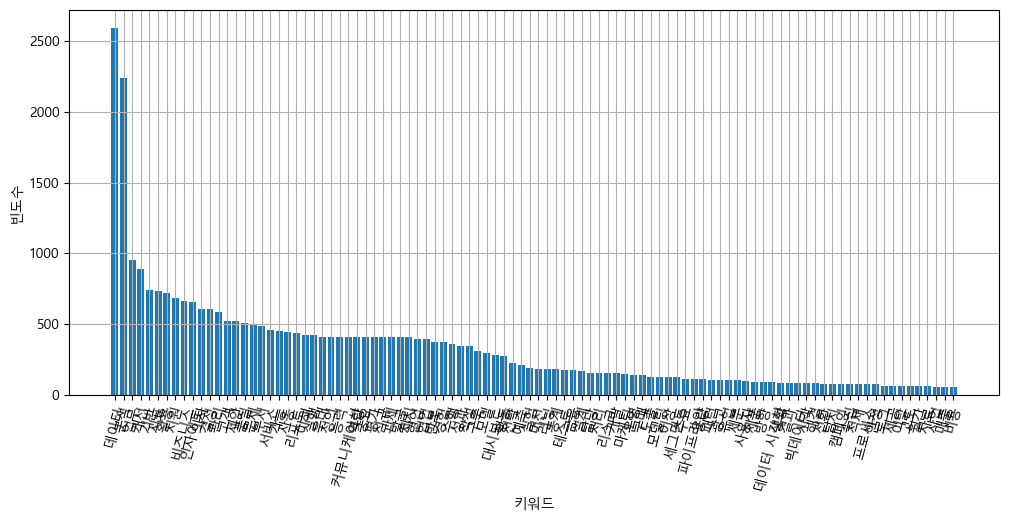

In [81]:
plt.figure(figsize = (12, 5))
plt.xlabel('키워드')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

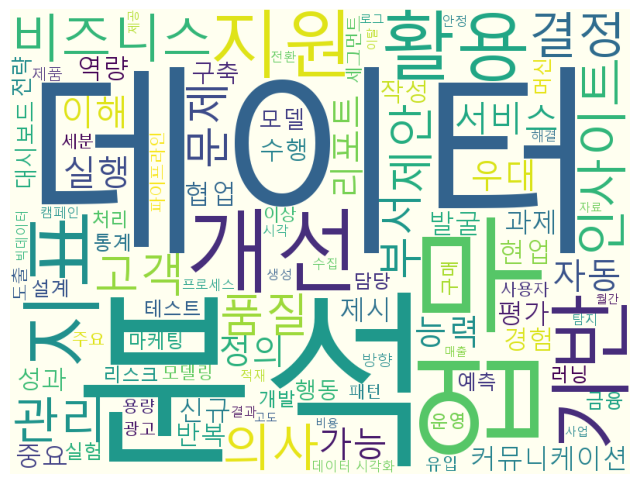

In [82]:
wc = WordCloud( font_path, background_color = 'ivory', width = 800, height = 600)
cloud = wc.generate_from_frequencies(word_count)
plt.figure(figsize = (8, 8))
plt.imshow(cloud)
plt.axis('off')
plt.show()

In [32]:
data.head(2)

,posting_id,company,job,industry,region,experience,required_years,salary,education,employment_type,remote_type,company_size,skill,posting_date,posting_month,deadline_days,openings,applicants,welfare_score,description
0,JOB0001,하이퍼커머스,데이터 분석가,물류,서울,1~3년,3,4600,학사,정규직,출근,중소기업,"SQL, Excel",2026-11-05,2026-11,8,2,106,4.4,"비즈니스 의사결정을 위한 데이터 분석, 리포트 작성, 대시보드 구축 업무를 수행합니..."
1,JOB0002,스마트리테일,경영 데이터 분석가,IT서비스,대전,신입,0,4800,학사,정규직,출근,대기업,"Power BI, KPI, Excel",2026-08-24,2026-08,41,1,198,3.0,"Power BI, KPI, Excel 기반으로 KPI 리포트와 월간 성과 분석 자료..."


In [35]:
data.shape

(2020, 20)

In [39]:
data.dtypes

posting_id         object
company            object
job                object
industry           object
region             object
experience         object
required_years      int64
salary             object
education          object
employment_type    object
remote_type        object
company_size       object
skill              object
posting_date       object
posting_month      object
deadline_days       int64
openings            int64
applicants         object
welfare_score      object
description        object
dtype: object

In [46]:
data.isnull().sum()

posting_id          0
company             0
job                 0
industry            0
region              0
experience         30
required_years      0
salary             19
education          30
employment_type     0
remote_type         0
company_size        0
skill               0
posting_date        0
posting_month       0
deadline_days       0
openings            0
applicants         18
welfare_score      35
description         0
dtype: int64

In [83]:
data_clean = data.dropna()

In [84]:
data_clean.isnull().sum()

posting_id         0
company            0
job                0
industry           0
region             0
experience         0
required_years     0
salary             0
education          0
employment_type    0
remote_type        0
company_size       0
skill              0
posting_date       0
posting_month      0
deadline_days      0
openings           0
applicants         0
welfare_score      0
description        0
dtype: int64

In [53]:
data_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1907 entries, 0 to 2019
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   posting_id       1907 non-null   object
 1   company          1907 non-null   object
 2   job              1907 non-null   object
 3   industry         1907 non-null   object
 4   region           1907 non-null   object
 5   experience       1907 non-null   object
 6   required_years   1907 non-null   int64 
 7   salary           1907 non-null   object
 8   education        1907 non-null   object
 9   employment_type  1907 non-null   object
 10  remote_type      1907 non-null   object
 11  company_size     1907 non-null   object
 12  skill            1907 non-null   object
 13  posting_date     1907 non-null   object
 14  posting_month    1907 non-null   object
 15  deadline_days    1907 non-null   int64 
 16  openings         1907 non-null   int64 
 17  applicants       1907 non-null   objec

In [85]:
data_clean = data_clean.drop_duplicates()

In [58]:
data_clean['posting_date']

0       2026-11-05
1       2026-08-24
2       2026-12-26
3       2026-09-13
4       2026-12-15
           ...    
1994    2026-12-21
1995    2026-06-05
1996    2026-04-08
1997    2026-09-28
1998    2026-03-29
Name: posting_date, Length: 1888, dtype: object

In [89]:
pattern =r'^\d{4}-\d{2}-\d{2}$'
count_w = 0
count_w = (data_clean['posting_date'].astype(str).str.match(pattern) == False).sum()
data_clean['posting_date'] = pd.to_datetime(data_clean['posting_date'], errors='coerce')
data_clean = data_clean.dropna()
count_w

np.int64(0)

In [94]:
data_clean['region'].value_counts()

region
서울    778
경기    470
부산    108
인천     97
대구     88
대전     66
강원     63
제주     53
광주     51
세종     35
Name: count, dtype: int64

In [104]:
data_clean['region'] = data_clean['region'].str.lower().str.strip()
is_seoul = data_clean['region'].str.contains('서울|seoul', case=False, na=False)
data_clean.loc[is_seoul, 'region'] = '서울'
is_gyung = data_clean['region'].str.contains('경기|gyeonggi', case=False, na=False)
data_clean.loc[is_gyung, 'region'] = '경기'
is_dae = data_clean['region'].str.contains('대구', case=False, na=False)
data_clean.loc[is_dae, 'region'] = '대구'
is_in = data_clean['region'].str.contains('인천', case=False, na=False)
data_clean.loc[is_in, 'region'] = '인천'
is_daej = data_clean['region'].str.contains('대전|daejeon', case=False, na=False)
data_clean.loc[is_daej, 'region'] = '대전'
is_bu = data_clean['region'].str.contains('부산', case=False, na=False)
data_clean.loc[is_bu, 'region'] = '부산'
is_je = data_clean['region'].str.contains('제주', case=False, na=False)
data_clean.loc[is_je, 'region'] = '제주'

In [103]:
data_clean.head(1)

,posting_id,company,job,industry,region,experience,required_years,salary,education,employment_type,remote_type,company_size,skill,posting_date,posting_month,deadline_days,openings,applicants,welfare_score,description
0,JOB0001,하이퍼커머스,데이터 분석가,물류,서울,1~3년,3,4600,학사,정규직,출근,중소기업,"SQL, Excel",2026-11-05,2026-11,8,2,106,4.4,"비즈니스 의사결정을 위한 데이터 분석, 리포트 작성, 대시보드 구축 업무를 수행합니..."


In [110]:
stopWords = set(stopwords.words("english"))
lemma = WordNetLemmatizer()

In [97]:
data_clean['skill'].value_counts()

skill
Python, SQL                   21
SQL, Python                   16
Tableau, SQL                  12
머신러닝, Python                   7
통계, Python                     7
                              ..
마케팅 성과분석, SQL, Python          1
이상탐지, SQL, 금융 데이터, 통계          1
통계, Pandas, 머신러닝               1
대용량 데이터, SQL, Spark, Hive      1
Retention, 고객세분화, Churn 분석     1
Name: count, Length: 1332, dtype: int64

In [115]:
all_skills = " ".join(data_clean['skill'].dropna().astype(str))
skill = re.sub(r'[^\w]', ' ', all_skills)
skill = skill.lower().strip()
EnWords = re.sub(r"[^a-zA-Z]+", " ", skill)
EnWordsToken = word_tokenize(EnWords.lower())
EnWordsTokenStop = [w for w in EnWordsToken if w not in stopWords]
EnWordsTokenStopLemma = [lemma.lemmatize(w) for w in EnWordsTokenStop]
words = EnWordsTokenStopLemma

In [118]:
count = Counter(words)
count

Counter({'sql': 818,
         'python': 750,
         'tableau': 306,
         'excel': 249,
         'b': 183,
         'panda': 179,
         'crm': 146,
         'spark': 145,
         'bi': 124,
         'power': 123,
         'matplotlib': 120,
         'amplitude': 90,
         'google': 80,
         'analytics': 80,
         'looker': 78,
         'scikit': 69,
         'learn': 69,
         'hadoop': 67,
         'llm': 62,
         'airflow': 62,
         'pytorch': 62,
         'etl': 62,
         'hive': 61,
         'kpi': 57,
         'ai': 57,
         'churn': 53,
         'retention': 48,
         'tensorflow': 46,
         'm': 3,
         'apache': 3,
         'statistic': 2,
         'structured': 2,
         'query': 2,
         'language': 2,
         'machine': 1,
         'learning': 1})

In [119]:
data_clean['salary'].value_counts()

salary
5300         81
5200         77
5100         75
5500         69
5400         69
             ..
8400          1
5700~         1
5600~         1
5500~6100     1
3800~4400     1
Name: count, Length: 83, dtype: int64

In [124]:
salary_clean = data_clean['salary'].astype(str).str.split('~').str[0]
salary_clean = salary_clean.str.replace(r'[^\d]', '', regex=True)
salary_numeric = pd.to_numeric(salary_clean, errors='coerce')
data_clean['salary'] = data_clean['salary'].fillna(salary_numeric.mean())

In [125]:
app_clean = data_clean['applicants'].astype(str).str.split('~').str[0]
app_clean = app_clean.str.replace(r'[^\d]', '', regex=True)
app_numeric = pd.to_numeric(app_clean, errors='coerce')
data_clean['applicants'] = data_clean['applicants'].fillna(app_numeric.mean())

In [127]:
data_clean['applicants']

0       106
1       198
2       330
3       239
4        37
       ... 
1994    328
1995    260
1996    240
1997    337
1998    141
Name: applicants, Length: 1809, dtype: object

In [128]:
description = ''
all_text = " ".join(data_clean['description'].dropna().astype(str))
description = re.sub(r'[^\w]', ' ', all_text)
description

'비즈니스 의사결정을 위한 데이터 분석  리포트 작성  대시보드 구축 업무를 수행합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  Power BI  KPI  Excel 기반으로 KPI 리포트와 월간 성과 분석 자료를 작성합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  사업 성과  매출  비용 데이터를 분석하여 경영진 의사결정을 지원합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  광고 성과와 고객 유입 데이터를 분석하여 마케팅 전략을 개선합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  A B 테스트  대시보드를 활용하여 사용자 행동 데이터를 분석하고 실험 설계를 지원합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  AI 서비스 데이터를 분석하고 생성형 AI 기반 업무 자동화를 지원합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  고객 행동 패턴을 분석하고 서비스 개선을 위한 인사이트를 도출합니다  현업 부서와 협업하여 데이터 기반 의사결정을 지원합니다  비즈니스 의사결정을 위한 데이터 분석  리포트 작성  대시보드 구축 업무를 수행합니다  비즈니스 지표를 이해하고 실행 가능한 인사이트를 제안할 수 있어야 합니다  서비스 지표 분석과 A B 테스트를 통해 제품 개선 방향을 제안합니다  문제 정의 능력과 커뮤니케이션 역량을 중요하게 평가합니다  Python  Scikit Learn  모델링  머신러닝를 활용하여 예측 모델을 개발하고 실험 결과를 분석합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  Matplotlib  Pandas  Python를 활용하여 서비스 데이터를 분석하고 주요 지표를 개선합니다  신규 데이터 분석 과제를 발굴하고 개선안을 제시합니다  서비스 지표 분석과 A B 테스트를 통해 제품 개선 방향을 제안합니다  데이터 품질 관리와 반복 업무 자동화 경험이 있으면 우대합니다  KPI  SQL 기반으로 KPI 리포트와 월간 성과 분석 자료를

In [134]:
kiwi = Kiwi()

description_N = [
    token.form
    for token in kiwi.tokenize(description)
    if token.tag.startswith('N')
]
count = Counter(description_N)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

데이터 : 2320
분석 : 2012
업무 : 866
개선 : 800
기반 : 661
활용 : 643
지표 : 643
지원 : 601
비즈니스 : 588
인사이트 : 570
의사 : 543
결정 : 543
관리 : 530
제안 : 458
고객 : 457
품질 : 456
문제 : 445
부서 : 436
리포트 : 403
서비스 : 401


In [135]:
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties( fname = font_path).get_name()
matplotlib.rc('font', family = font_name)

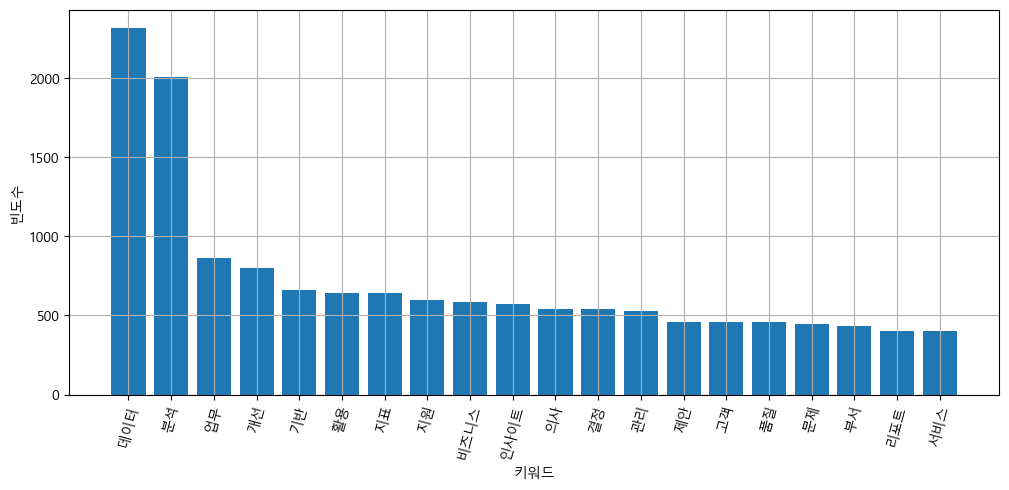

In [136]:
plt.figure(figsize = (12, 5))
plt.xlabel('키워드')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

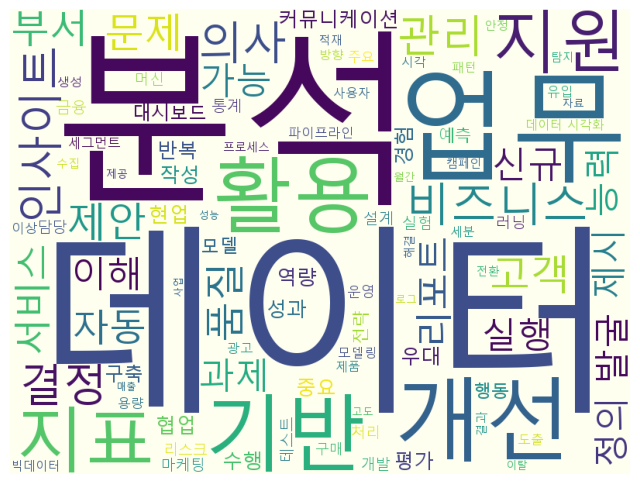

In [132]:
wc = WordCloud( font_path, background_color = 'ivory', width = 800, height = 600)
cloud = wc.generate_from_frequencies(word_count)
plt.figure(figsize = (8, 8))
plt.imshow(cloud)
plt.axis('off')
plt.show()

In [140]:
region = ''
all_region = " ".join(data_clean['region'].dropna().astype(str))
region = re.sub(r'[^\w]', ' ', all_region)

region_N = [
    token.form
    for token in kiwi.tokenize(region)
    if token.tag.startswith('N')
]
count = Counter(region_N)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

서울 : 778
경기 : 470
부산 : 108
인천 : 97
대구 : 88
대전 : 66
강원 : 63
제주 : 53
광주 : 51
세종 : 35


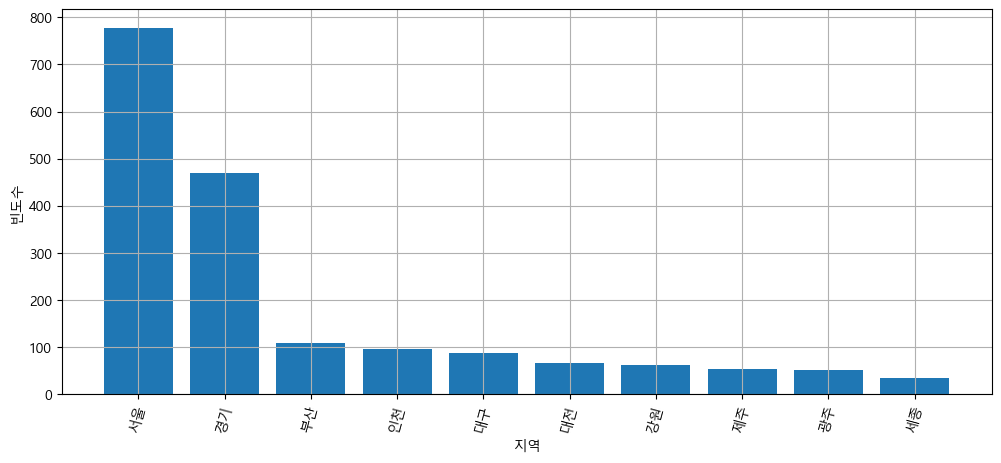

In [141]:
plt.figure(figsize = (12, 5))
plt.xlabel('지역')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [142]:
industry = ''
all_industry = " ".join(data_clean['industry'].dropna().astype(str))
industry = re.sub(r'[^\w]', ' ', all_industry)
industry_N = [
    token.form
    for token in kiwi.tokenize(industry)
    if token.tag.startswith('N')
]
count = Counter(industry_N)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

커머스 : 171
콘텐츠 : 159
교육 : 155
금융 : 152
통신 : 152
유통 : 150
제조 : 147
게임 : 146
서비스 : 145
모빌리티 : 145
헬스케어 : 145
물류 : 141
IT서비스 : 1


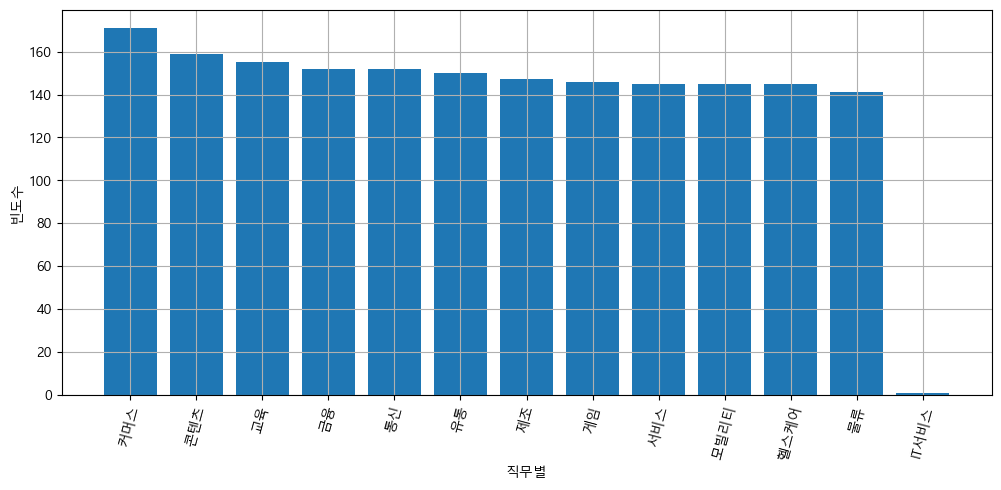

In [143]:
plt.figure(figsize = (12, 5))
plt.xlabel('산업군')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [144]:
job = ''
all_job = " ".join(data_clean['job'].dropna().astype(str))
job = re.sub(r'[^\w]', ' ', all_job)
job_N = [
    token.form
    for token in kiwi.tokenize(job)
    if token.tag.startswith('N')
]
count = Counter(job_N)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

데이터 : 1526
분석가 : 1521
프로덕트 : 175
마케팅 : 172
사이언티스트 : 154
빅데이터 : 140
엔지니어 : 134
고객 : 124
경영 : 108
금융 : 108
리스크 : 89


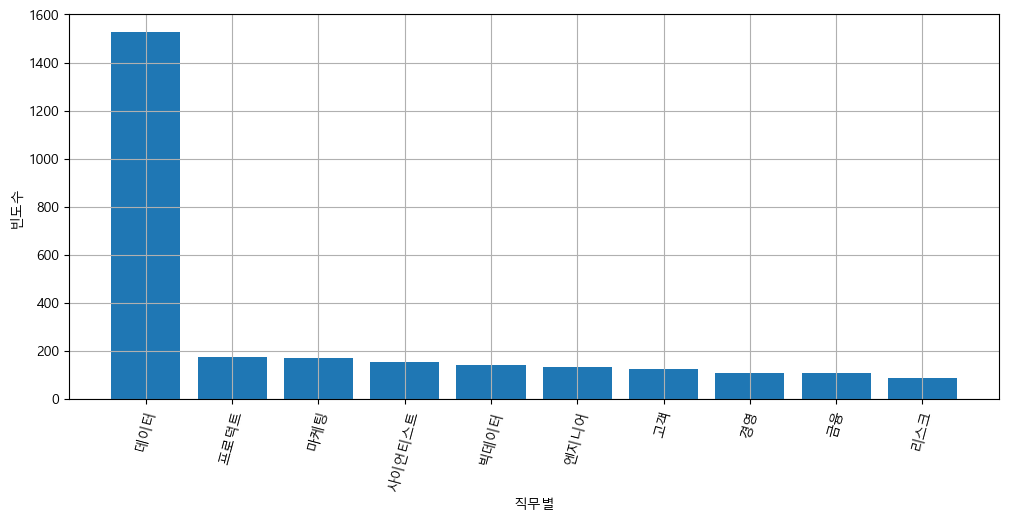

In [148]:
plt.figure(figsize = (12, 5))
plt.xlabel('직무별')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [149]:
education = ''
all_education = " ".join(data_clean['education'].dropna().astype(str))
education = re.sub(r'[^\w]', ' ', all_education)
education_N = [
    token.form
    for token in kiwi.tokenize(education)
    if token.tag.startswith('N')
]
count = Counter(education_N)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

학사 : 1089
석사 : 327
무관 : 288
학력 : 275
박사 : 90
전문 : 88
이상 : 16
전문학사 : 15


In [151]:
del word_count['이상']

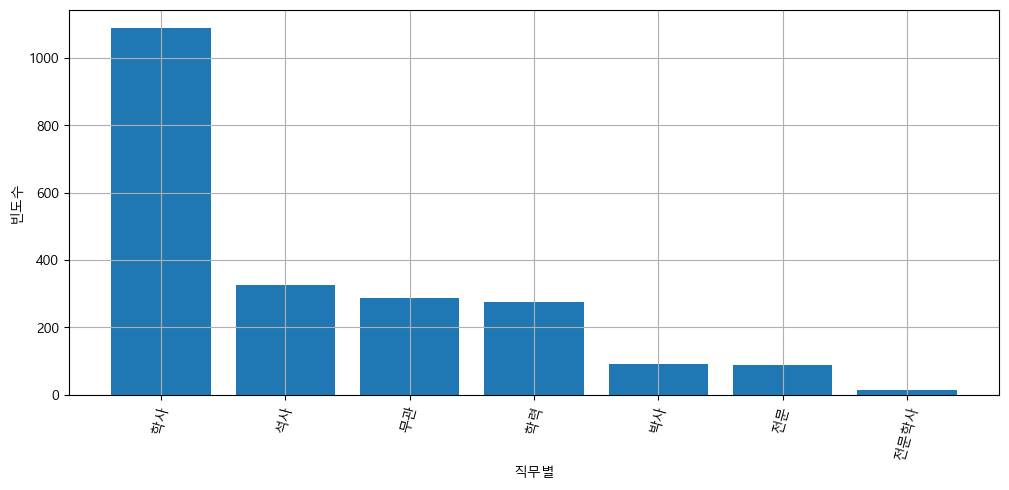

In [152]:
plt.figure(figsize = (12, 5))
plt.xlabel('직무별')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [155]:
all_skills = " ".join(data_clean['skill'].dropna().astype(str))
skill = re.sub(r'[^\w]', ' ', all_skills)
skill = skill.lower().strip()
EnWords = re.sub(r"[^a-zA-Z]+", " ", skill)
EnWordsToken = word_tokenize(EnWords.lower())
EnWordsTokenStop = [w for w in EnWordsToken if w not in stopWords]
EnWordsTokenStopLemma = [lemma.lemmatize(w) for w in EnWordsTokenStop]
words = EnWordsTokenStopLemma
count = Counter(words)
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

sql : 818
python : 750
tableau : 306
excel : 249
panda : 179
crm : 146
spark : 145
bi : 124
power : 123
matplotlib : 120
amplitude : 90
google : 80
analytics : 80
looker : 78
scikit : 69
learn : 69
hadoop : 67
llm : 62
airflow : 62


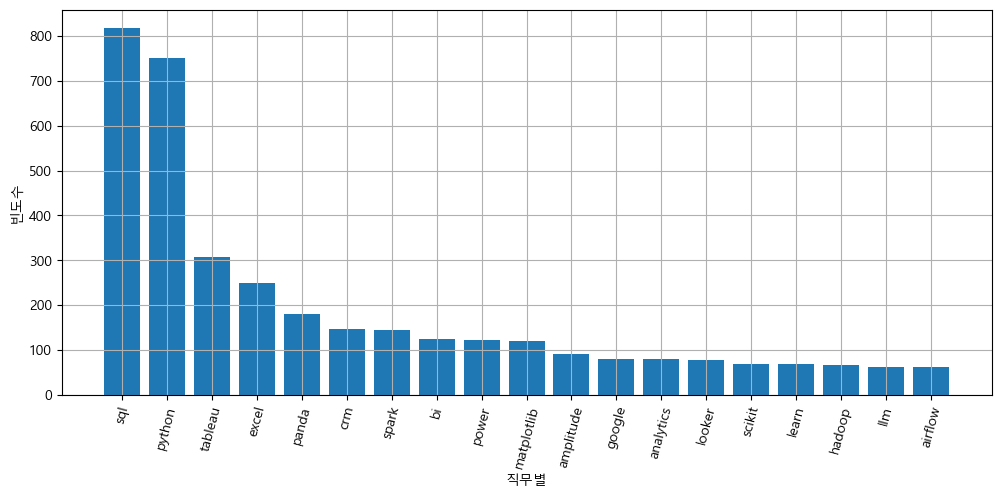

In [156]:
plt.figure(figsize = (12, 5))
plt.xlabel('직무별')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

In [163]:
month_clean = data_clean['posting_month'].astype(str).str.split('-').str[1]
data_clean['month'] = month_clean
data_clean['month']

0       11
1       08
2       12
3       09
4       12
        ..
1994    12
1995    06
1996    04
1997    09
1998    03
Name: month, Length: 1809, dtype: object

In [164]:
count = Counter(data_clean['month'])
word_count = dict()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

04 : 173
12 : 168
01 : 161
10 : 158
09 : 154
06 : 150
05 : 148
03 : 148
08 : 145
07 : 144
11 : 133
02 : 127


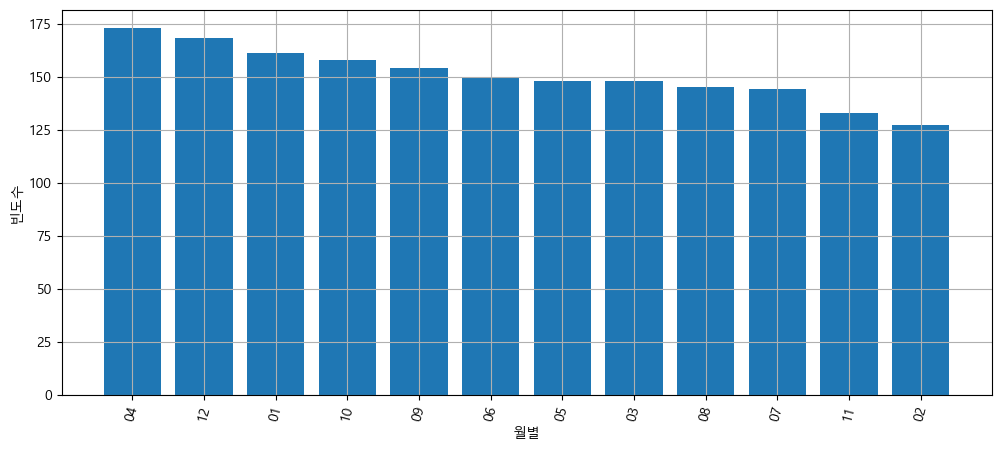

In [165]:
plt.figure(figsize = (12, 5))
plt.xlabel('월별')
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

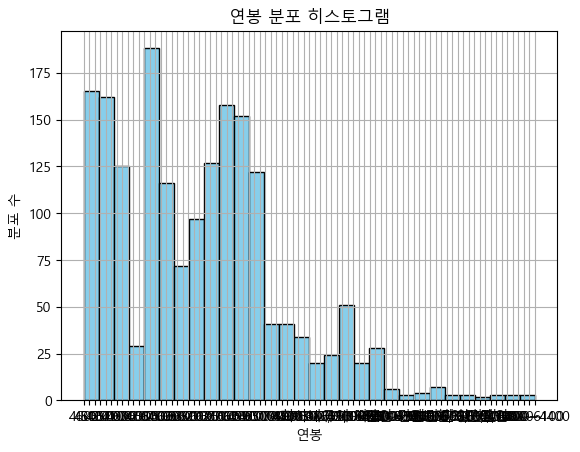

In [172]:
data_clean['salary'].hist(bins=30, color='skyblue', edgecolor='black')

plt.title('연봉 분포 히스토그램')
plt.xlabel('연봉')
plt.ylabel('분포 수')
plt.show()

In [176]:
count = Counter(data_clean['company_size'])
word_count = dict()
data_clean['salary'] = pd.to_numeric(data_clean['salary'], errors='coerce')
normal = data_clean.groupby('company_size')['salary'].mean()
#20개까지만
for tag, counts in count.most_common(20):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

중소기업 : 612
스타트업 : 499
중견기업 : 402
대기업 : 296


📊 [회사 규모별 채용 공고 개수]
중소기업 : 612
스타트업 : 499
중견기업 : 402
대기업 : 296


([<matplotlib.axis.XTick at 0x16f370312e0>,
 [Text(0, 0, '대기업'),
  Text(1, 0, '중견기업'),
  Text(2, 0, '스타트업'),
  Text(3, 0, '중소기업')])

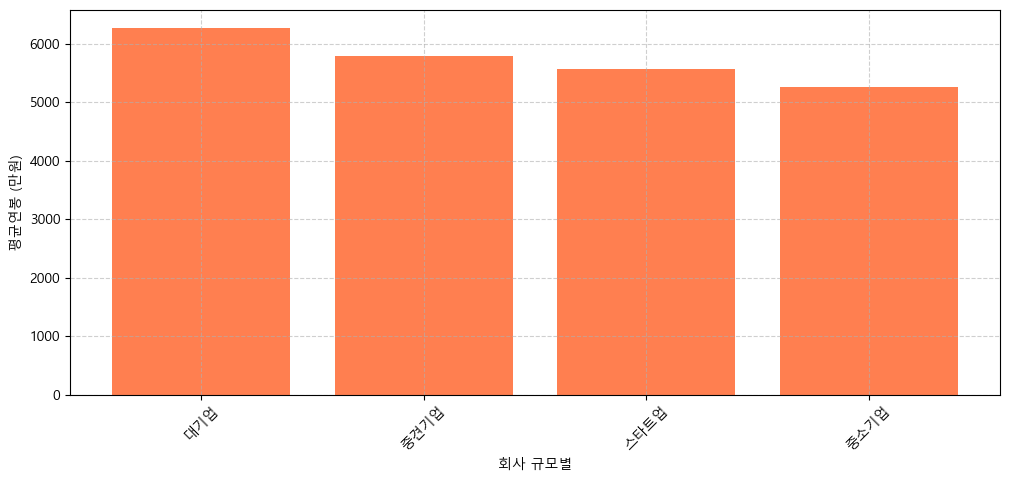

In [178]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# ========================================================
# 1단계: 회사 규모별 공고 개수 세기 및 1글자 필터링
# ========================================================
count = Counter(data_clean['company_size'].dropna())
valid_sizes = []

print("📊 [회사 규모별 채용 공고 개수]")
for tag, counts in count.most_common(20):
    if len(str(tag)) > 1:
        valid_sizes.append(tag) # 유효한 회사 규모 이름을 리스트에 저장
        print(f"{tag} : {counts}")
size_salary = data_clean.groupby('company_size')['salary'].mean()

# 위에서 구한 평균 연봉 데이터 중, 유효한 규모들만 쏙 뽑아오고 
# 연봉이 높은 순서(내림차순)로 예쁘게 정렬합니다.
filtered_salary = size_salary.loc[size_salary.index.isin(valid_sizes)].sort_values(ascending=False)
filtered_salary = size_salary.loc[size_salary.index.isin(valid_sizes)].sort_values(ascending=False)


# ========================================================
# 3단계: 시각화 막대그래프 그리기
# ========================================================
# 정렬된 데이터에서 키(회사규모)와 값(평균연봉)을 추출합니다.
sorted_Keys = list(filtered_salary.index)
sorted_Values = list(filtered_salary.values)

plt.figure(figsize=(12, 5))
# 💡 축 이름을 질문자님의 의도인 '평균연봉'에 맞게 세팅합니다!
plt.xlabel('회사 규모별')
plt.ylabel('평균연봉 (만원)')
plt.grid(True, linestyle='--', alpha=0.6)

# 계산된 평균연봉 값의 개수만큼 정확하게 막대 세우기
plt.bar(range(len(sorted_Values)), sorted_Values, align='center', color='coral')
plt.xticks(range(len(sorted_Keys)), sorted_Keys, rotation=45)

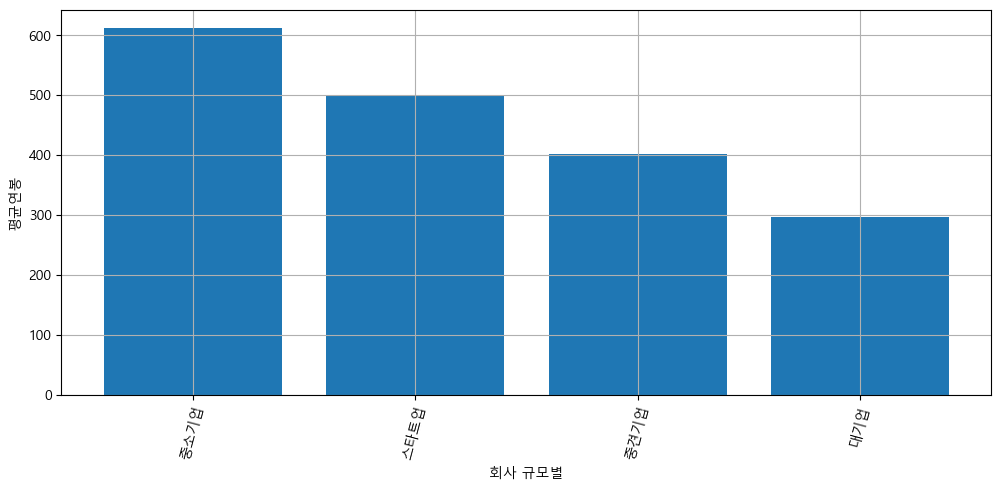

In [174]:
plt.figure(figsize = (12, 5))
plt.xlabel('회사 규모별')
plt.ylabel('평균연봉')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()